In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import pandas as pd

In [5]:
df = pd.read_csv("../data/doctor_visits.csv")

In [6]:
df.shape

(5190, 13)

In [7]:
df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [8]:
df.columns

Index(['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced',
       'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   str    
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   str    
 9   freepoor    5190 non-null   str    
 10  freerepat   5190 non-null   str    
 11  nchronic    5190 non-null   str    
 12  lchronic    5190 non-null   str    
dtypes: float64(2), int64(5), str(6)
memory usage: 527.2 KB


In [10]:
df.isnull().sum()

Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [13]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts())


gender
gender
female    2702
male      2488
Name: count, dtype: int64

private
private
no     2892
yes    2298
Name: count, dtype: int64

freepoor
freepoor
no     4968
yes     222
Name: count, dtype: int64

freerepat
freerepat
no     4099
yes    1091
Name: count, dtype: int64

nchronic
nchronic
no     3098
yes    2092
Name: count, dtype: int64

lchronic
lchronic
no     4585
yes     605
Name: count, dtype: int64


C:\Users\anusr\AppData\Local\Temp\ipykernel_24000\2375664890.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [14]:
df_clean = df.copy()
df_clean.isnull().sum()

Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

In [15]:
df_clean.duplicated().sum()

np.int64(0)

In [16]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   str    
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   str    
 9   freepoor    5190 non-null   str    
 10  freerepat   5190 non-null   str    
 11  nchronic    5190 non-null   str    
 12  lchronic    5190 non-null   str    
dtypes: float64(2), int64(5), str(6)
memory usage: 527.2 KB


In [17]:
for column in df_clean.columns:
    print(f"\n{column}")
    print(df_clean[column].unique()[:20])


Unnamed: 0
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]

visits
[1 2 3 4 8 5 7 6 9 0]

gender
<StringArray>
['female', 'male']
Length: 2, dtype: str

age
[0.19 0.22 0.27 0.32 0.37 0.42 0.47 0.52 0.57 0.62 0.67 0.72]

income
[0.55 0.45 0.9  0.15 0.35 0.65 0.25 0.   0.06 1.1  0.75 0.01 1.3  1.5 ]

illness
[1 3 2 5 4 0]

reduced
[ 4  2  0  5  1 13  7  3 14  6  8  9 10 12 11]

health
[ 1  0  9  2  6  5  7 11  4 12  3 10  8]

private
<StringArray>
['yes', 'no']
Length: 2, dtype: str

freepoor
<StringArray>
['no', 'yes']
Length: 2, dtype: str

freerepat
<StringArray>
['no', 'yes']
Length: 2, dtype: str

nchronic
<StringArray>
['no', 'yes']
Length: 2, dtype: str

lchronic
<StringArray>
['no', 'yes']
Length: 2, dtype: str


In [18]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,5190.0,2595.500000,1498.368279,1.00,1298.25,2595.50,3892.75,5190.00
visits,5190.0,0.301734,0.798134,0.00,0.00,0.00,0.00,9.00
age,5190.0,0.406385,0.204782,0.19,0.22,0.32,0.62,0.72
income,5190.0,0.583160,0.368907,0.00,0.25,0.55,0.90,1.50
illness,5190.0,1.431985,1.384152,0.00,0.00,1.00,2.00,5.00
reduced,5190.0,0.861850,2.887628,0.00,0.00,0.00,0.00,14.00
health,5190.0,1.217534,2.124266,0.00,0.00,0.00,2.00,12.00


In [19]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 18, 30, 45, 60, 75, 100],
    labels=["0-18", "19-30", "31-45", "46-60", "61-75", "76+"],
    include_lowest=True
)

In [20]:
df_clean["age_group"].value_counts().sort_index()

age_group
0-18     5190
19-30       0
31-45       0
46-60       0
61-75       0
76+         0
Name: count, dtype: int64

In [21]:
df_clean["visits"].describe()
df_clean["visits"].value_counts().sort_index()

visits
0    4141
1     782
2     174
3      30
4      24
5       9
6      12
7      12
8       5
9       1
Name: count, dtype: int64

In [22]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (5190, 13)
Cleaned shape: (5190, 14)


In [23]:
df_clean.to_csv("../data/doctor_visits_cleaned.csv", index=False)

In [24]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())

Rows: 5190
Columns: 14
Missing values: 0
Duplicates: 0


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

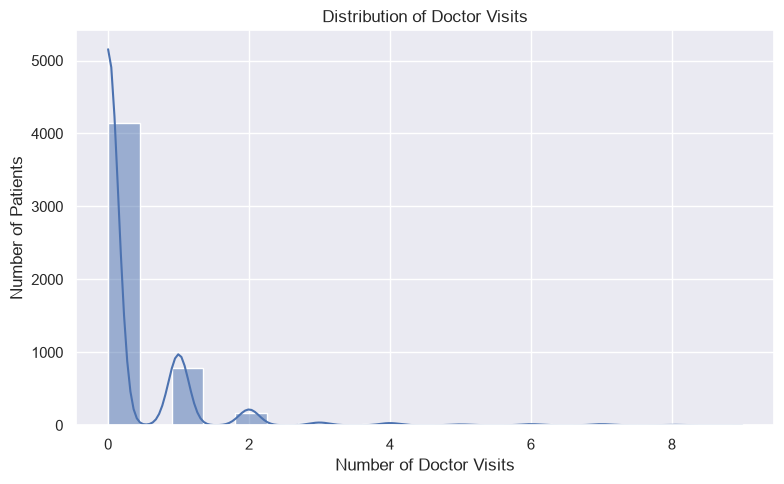

In [38]:
import os
os.makedirs("../charts", exist_ok=True)

plt.figure(figsize=(8, 5))
sns.histplot(df_clean["visits"], bins=20, kde=True)
plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of Doctor Visits")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.savefig("../charts/01_doctor_visit_distribution.png", dpi=300)
plt.show()

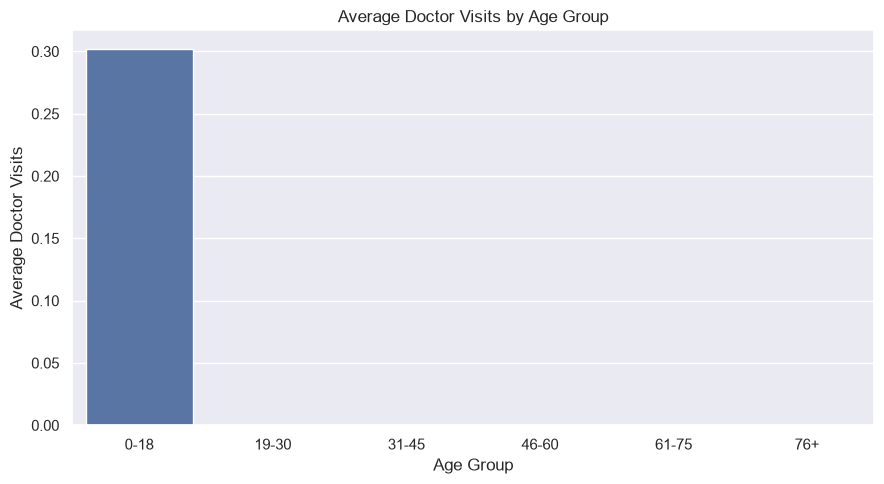

In [39]:
age_visits = df_clean.groupby("age_group", observed=True)["visits"].mean().reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(data=age_visits, x="age_group", y="visits")
plt.title("Average Doctor Visits by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/02_average_visits_by_age_group.png", dpi=300)
plt.show()

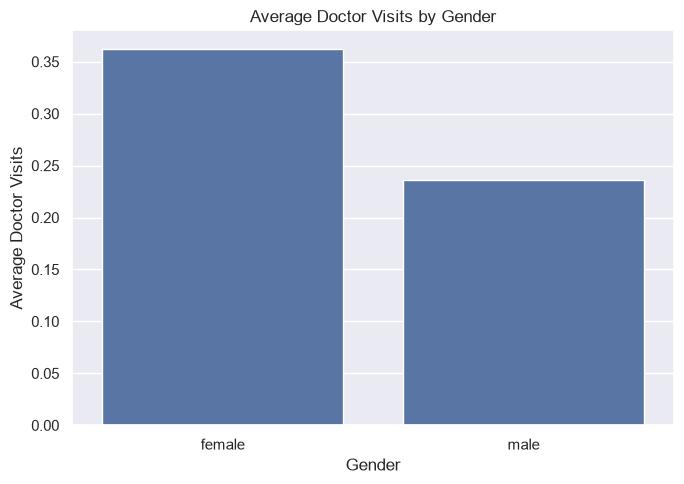

In [40]:
gender_visits = df_clean.groupby("gender")["visits"].mean().reset_index()

plt.figure(figsize=(7, 5))
sns.barplot(data=gender_visits, x="gender", y="visits")
plt.title("Average Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/03_average_visits_by_gender.png", dpi=300)
plt.show()

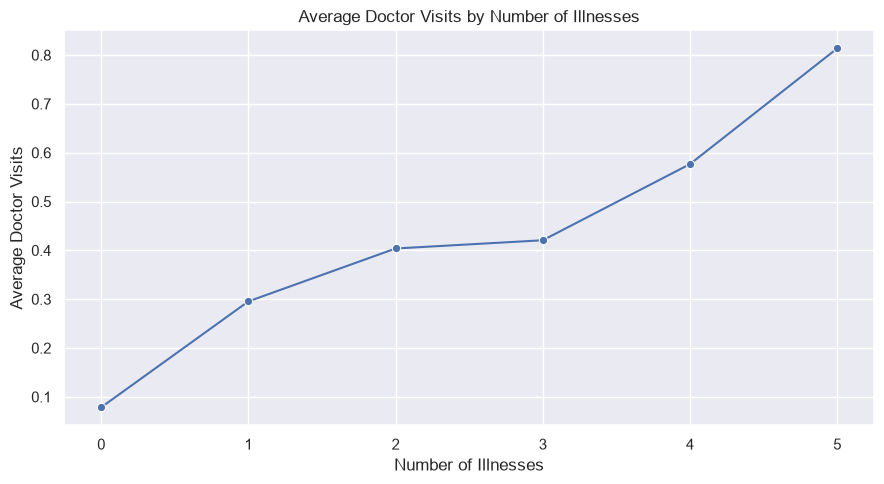

In [41]:
illness_visits = df_clean.groupby("illness")["visits"].mean().reset_index()

plt.figure(figsize=(9, 5))
sns.lineplot(data=illness_visits, x="illness", y="visits", marker="o")
plt.title("Average Doctor Visits by Number of Illnesses")
plt.xlabel("Number of Illnesses")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/04_average_visits_by_illness_count.png", dpi=300)
plt.show()

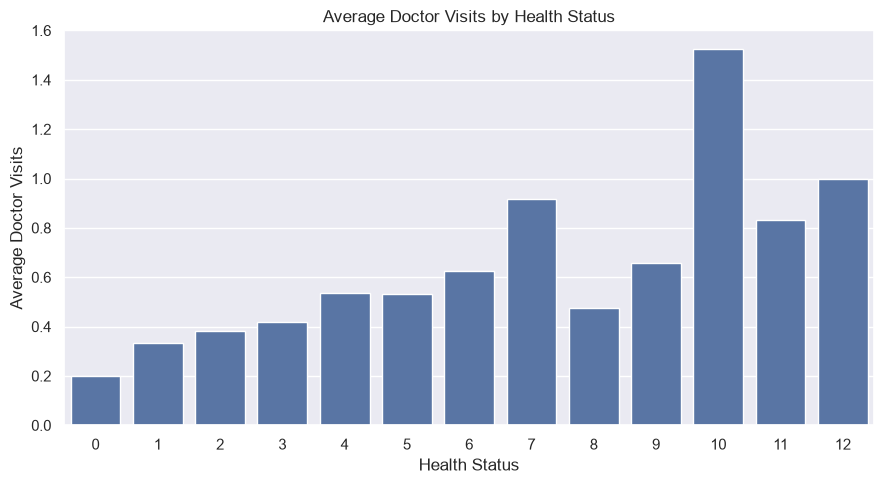

In [42]:
health_visits = df_clean.groupby("health")["visits"].mean().reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(data=health_visits, x="health", y="visits")
plt.title("Average Doctor Visits by Health Status")
plt.xlabel("Health Status")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/05_average_visits_by_health_status.png", dpi=300)
plt.show()

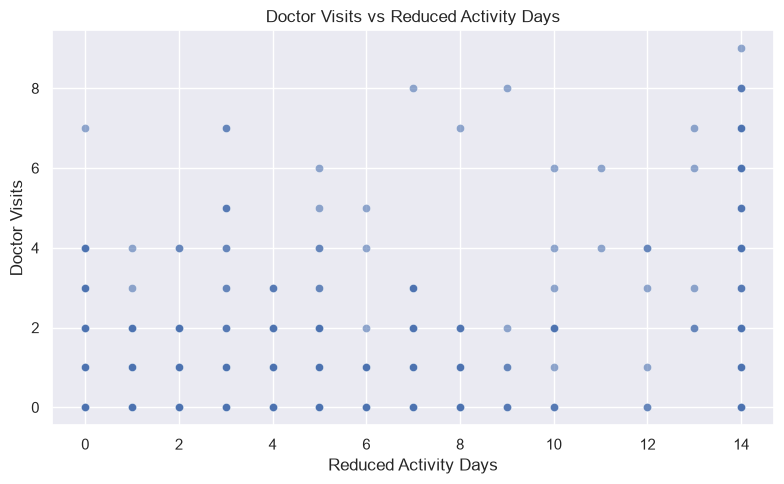

In [43]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="reduced", y="visits", alpha=0.6)
plt.title("Doctor Visits vs Reduced Activity Days")
plt.xlabel("Reduced Activity Days")
plt.ylabel("Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/06_visits_vs_reduced_activity.png", dpi=300)
plt.show()

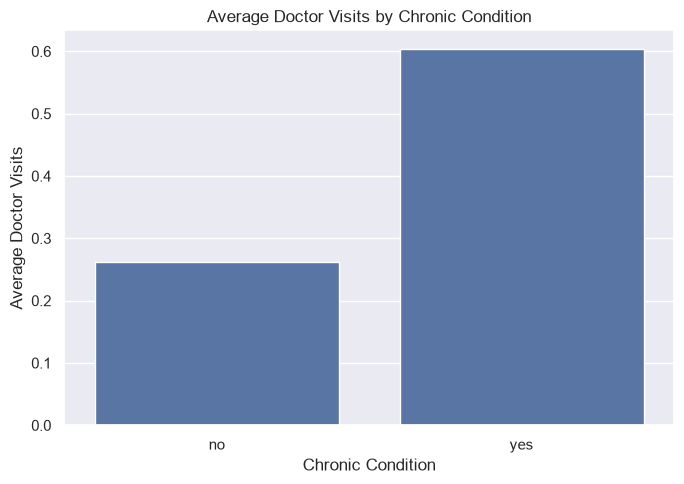

In [44]:
chronic_visits = df_clean.groupby("lchronic")["visits"].mean().reset_index()

plt.figure(figsize=(7, 5))
sns.barplot(data=chronic_visits, x="lchronic", y="visits")
plt.title("Average Doctor Visits by Chronic Condition")
plt.xlabel("Chronic Condition")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/07_average_visits_by_chronic_condition.png", dpi=300)
plt.show()

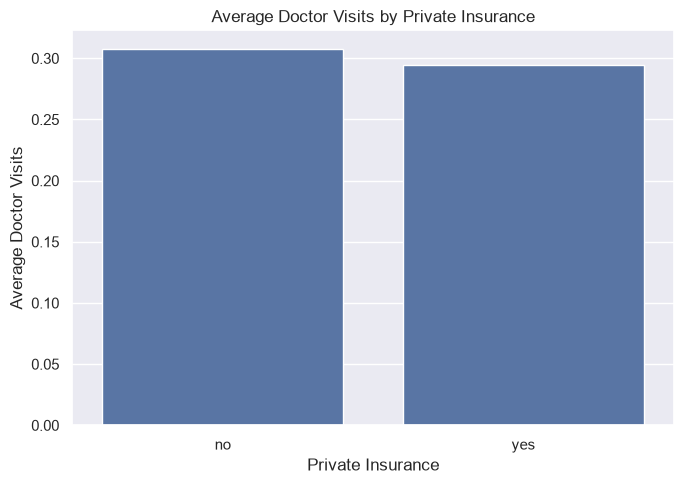

In [45]:
insurance_visits = df_clean.groupby("private")["visits"].mean().reset_index()

plt.figure(figsize=(7, 5))
sns.barplot(data=insurance_visits, x="private", y="visits")
plt.title("Average Doctor Visits by Private Insurance")
plt.xlabel("Private Insurance")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/08_average_visits_by_private_insurance.png", dpi=300)
plt.show()

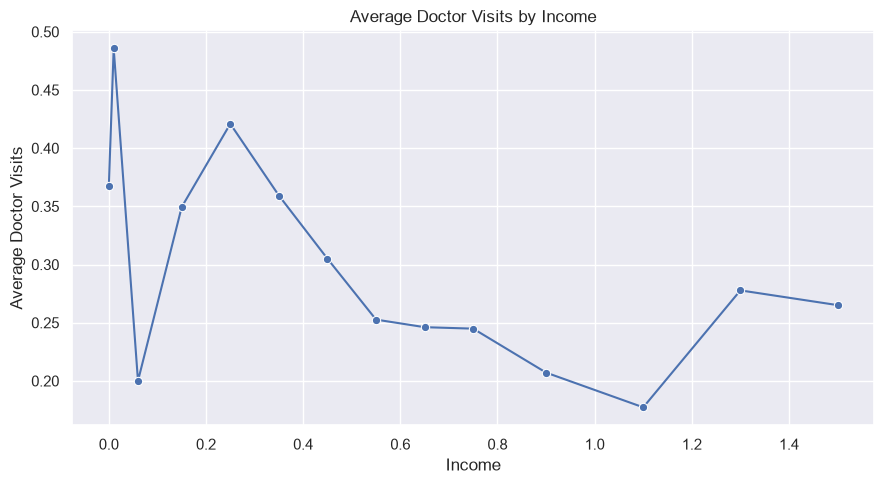

In [46]:
income_visits = df_clean.groupby("income")["visits"].mean().reset_index()

plt.figure(figsize=(9, 5))
sns.lineplot(data=income_visits, x="income", y="visits", marker="o")
plt.title("Average Doctor Visits by Income")
plt.xlabel("Income")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("../charts/09_average_visits_by_income.png", dpi=300)
plt.show()

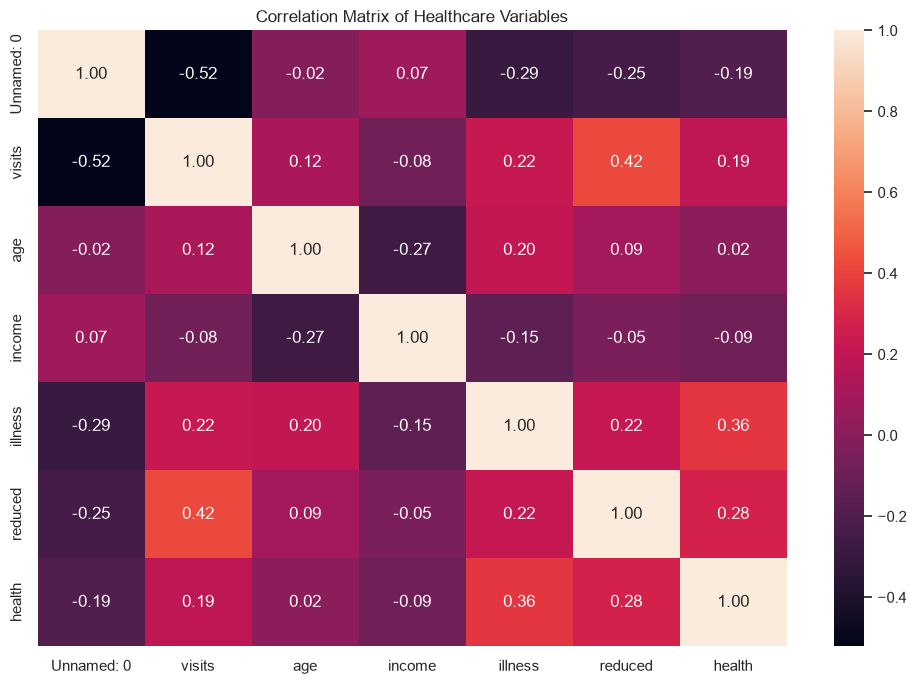

In [47]:
numeric_df = df_clean.select_dtypes(include="number")

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f")
plt.title("Correlation Matrix of Healthcare Variables")
plt.tight_layout()
plt.savefig("../charts/10_healthcare_correlation_matrix.png", dpi=300)
plt.show()

In [36]:
import os

os.makedirs("../charts", exist_ok=True)

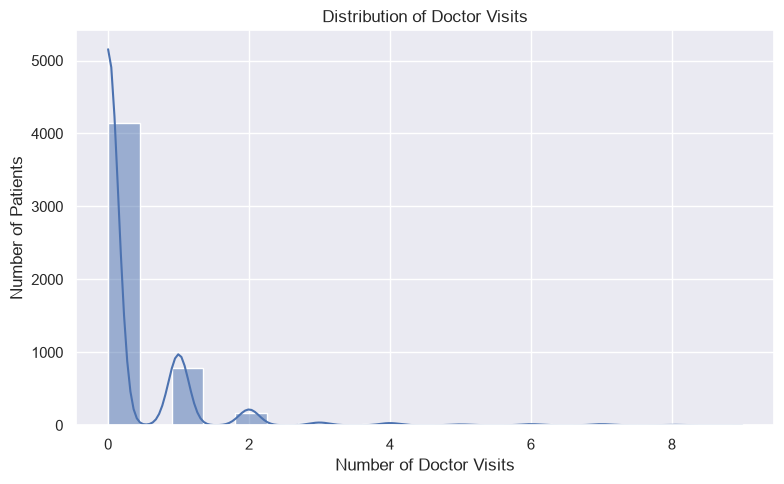

In [37]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["visits"], bins=20, kde=True)
plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of Doctor Visits")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.savefig("../charts/01_doctor_visit_distribution.png", dpi=300)
plt.show()